# Notebook 2: Vektorisasi Teks Soal LeetCode

Notebook ini mengubah teks hasil preprocessing jadi angka. Alasannya sederhana:
algoritma klasifikasi bekerja dengan matriks angka, bukan dengan kalimat.

### Tiga cara vektorisasi yang dibandingkan

1. **Bag of Words**, menghitung berapa kali tiap kata muncul
2. **TF-IDF**, memberi bobot berdasarkan seberapa khas sebuah kata
3. **N-gram**, menjaga pasangan kata berurutan supaya maknanya tidak pecah

### Prasyarat

Jalankan dulu `01_Pengambilan_Data.ipynb` sampai sel terakhir. Notebook itu
menghasilkan `Dataset/dataset_leetcode_cleaned.xlsx` yang dibaca di sini.

Dari berkas itu, dua kolom yang dipakai:

`Cleaned_Description` jadi X, teks yang divektorisasi.
`Difficulty` jadi y, label Easy, Medium, atau Hard.

### Catatan sebelum dijalankan

Pastikan kernel yang dipakai adalah **Python (Text-Mining .venv)**.

## Tahap 0: Import dan Menentukan Lokasi Dataset

Fungsi `cari_root` sama persis dengan yang ada di notebook pertama. Keduanya
mencari root project dengan cara yang sama, jadi kedua notebook selalu menunjuk ke
folder `Dataset` yang sama walaupun dijalankan dari lokasi berbeda.

Library utamanya dari scikit-learn: `CountVectorizer` untuk Bag of Words,
`TfidfVectorizer` untuk TF-IDF, dan `LabelEncoder` untuk mengubah label teks jadi
angka.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

import scipy.sparse as sp
import pickle


def cari_root(mulai: Path) -> Path:
    """Cari root project, yaitu folder yang memuat subfolder 'Praktikum'."""
    for p in (mulai, *mulai.parents):
        if (p / "Praktikum").is_dir():
            return p
    return mulai


ROOT = cari_root(Path.cwd().resolve())
DATASET_DIR = ROOT / "Dataset"

FILE_XLSX = DATASET_DIR / "dataset_leetcode_cleaned.xlsx"   # dihasilkan notebook 1

print(f"Root project  : {ROOT}")
print(f"Folder dataset: {DATASET_DIR}")
print(f"Berkas sumber : {FILE_XLSX}")

Root project  : /Users/alif/PycharmProjects/Text-Mining
Folder dataset: /Users/alif/PycharmProjects/Text-Mining/Dataset
Berkas sumber : /Users/alif/PycharmProjects/Text-Mining/Dataset/dataset_leetcode_cleaned.xlsx


## Tahap 1: Membaca Dataset dari Notebook Pertama

Inilah titik sambung antara kedua notebook. Notebook ini tidak mengulang scraping,
melainkan membaca berkas XLSX yang sudah dihasilkan sebelumnya.

Pengecekan `if not FILE_XLSX.exists()` sengaja ditaruh di awal supaya kalau
notebook pertama belum dijalankan, pesan errornya langsung jelas menyebutkan apa
yang harus dilakukan, bukan error panjang dari pandas.

In [2]:
# Berhenti dengan pesan yang jelas kalau notebook 1 belum dijalankan
if not FILE_XLSX.exists():
    raise FileNotFoundError(
        f"Berkas belum ada: {FILE_XLSX}\n"
        "Jalankan dulu 01_Pengambilan_Data.ipynb sampai sel terakhir."
    )

df = pd.read_excel(FILE_XLSX)

print(f"Berhasil membaca: {FILE_XLSX.name}")
print(f"Ukuran dataset  : {df.shape[0]} baris x {df.shape[1]} kolom")
print(f"Kolom           : {list(df.columns)}\n")
display(df.head())

Berhasil membaca: dataset_leetcode_cleaned.xlsx
Ukuran dataset  : 90 baris x 5 kolom
Kolom           : ['Problem Name', 'Category', 'Difficulty', 'Description', 'Cleaned_Description']



,Problem Name,Category,Difficulty,Description,Cleaned_Description
0,Two Sum,"Array, Hash Table",Easy,You are given an array of integers nums and an...,array integer nums integer target index two nu...
1,Longest Substring Without Repeating Characters,"Hash Table, String, Sliding Window",Medium,"Given a string s , find the length of the long...",string find length longest substring without d...
2,Median of Two Sorted Arrays,"Array, Binary Search, Divide and Conquer",Hard,Given two sorted arrays nums1 and nums2 of siz...,two sorted array nums nums size n respectively...
3,Longest Palindromic Substring,"Two Pointers, String, Dynamic Programming, Man...",Medium,"Given a string s , return the longest palindro...",string longest palindromic substring babad bab...
4,Zigzag Conversion,String,Medium,"The string ""PAYPALISHIRING"" is written in a zi...",string paypalishiring written zigzag pattern n...


Sel berikut memvalidasi datanya sebelum diproses.

Dua hal yang dicek: kolom yang dibutuhkan harus ada, dan baris yang teks bersihnya
kosong harus dibuang. Baris kosong akan jadi vektor nol yang tidak membawa
informasi apa apa dan cuma mengganggu perhitungan bobot.

Sebaran label ditampilkan lagi di sini sebagai pengingat bahwa datanya tidak
seimbang.

In [3]:
# Pastikan kolom yang dibutuhkan tersedia
kolom_wajib = ['Cleaned_Description', 'Difficulty']
hilang = [k for k in kolom_wajib if k not in df.columns]
if hilang:
    raise KeyError(f"Kolom {hilang} tidak ditemukan. Jalankan ulang notebook 1.")

# Buang baris yang teks bersihnya kosong (kalau ada)
sebelum = len(df)
df = df.dropna(subset=kolom_wajib)
df = df[df['Cleaned_Description'].astype(str).str.strip() != ""].reset_index(drop=True)
print(f"Baris terpakai: {len(df)} (dibuang {sebelum - len(df)} baris kosong)")

print("\nDistribusi label Difficulty:")
display(df['Difficulty'].value_counts())

Baris terpakai: 90 (dibuang 0 baris kosong)

Distribusi label Difficulty:


Difficulty
Medium    52
Hard      20
Easy      18
Name: count, dtype: int64

## Tahap 2: Menyiapkan X dan y

`X_teks` berisi kumpulan teks yang akan divektorisasi. `y` berisi labelnya.

`LabelEncoder` mengubah label teks jadi angka karena model tidak bisa memproses
string. Pemetaannya dicetak supaya jelas angka mana mewakili kelas mana.

Perhatikan urutannya: LabelEncoder mengurutkan berdasarkan abjad, jadi hasilnya
Easy jadi 0, Hard jadi 1, Medium jadi 2. Urutannya bukan dari mudah ke sulit.
Objek encoder ini nanti ikut disimpan, supaya saat prediksi angka bisa
dikembalikan lagi ke nama kelas yang benar.

In [4]:
X_teks = df['Cleaned_Description'].astype(str)
y_label = df['Difficulty']

encoder = LabelEncoder()
y = encoder.fit_transform(y_label)

print("Contoh teks (X):")
print(" ", X_teks.iloc[0][:150], "...\n")

print("Pemetaan label (y):")
for angka, nama in enumerate(encoder.classes_):
    print(f"  {nama:<8} -> {angka}")

print(f"\nJumlah dokumen: {len(X_teks)}")

Contoh teks (X):
  array integer nums integer target index two number add target may assume would exactly one solution may use element twice answer order nums target num ...

Pemetaan label (y):
  Easy     -> 0
  Hard     -> 1
  Medium   -> 2

Jumlah dokumen: 90


## Tahap 3: Bag of Words

Bag of Words mengubah tiap dokumen jadi baris berisi hitungan kata. Kolomnya
adalah seluruh kata unik yang ada di korpus, isinya berapa kali kata itu muncul di
dokumen tersebut.

Urutan kata diabaikan sepenuhnya, makanya disebut kantong kata. Kalimat "array of
integer" dan "integer of array" menghasilkan vektor yang sama persis.

Dua parameter yang dipakai untuk memangkas kosakata:

`min_df=2` membuang kata yang cuma muncul di satu dokumen. Kata seperti itu tidak
bisa dipakai untuk menggeneralisasi, cuma menambah kolom.

`max_df=0.85` membuang kata yang muncul di lebih dari 85 persen dokumen. Kata yang
ada di mana mana tidak membedakan apa apa.

In [5]:
bow_vectorizer = CountVectorizer(min_df=2, max_df=0.85)
X_bow = bow_vectorizer.fit_transform(X_teks)

fitur_bow = bow_vectorizer.get_feature_names_out()

print(f"Ukuran matriks Bag of Words : {X_bow.shape}  (dokumen x kata unik)")
print(f"Jumlah kata unik (vocabulary): {len(fitur_bow)}")
print(f"Sel tidak nol               : {X_bow.nnz:,} dari {X_bow.shape[0] * X_bow.shape[1]:,}")
print(f"Tingkat kejarangan (sparsity): {100 * (1 - X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])):.2f}%")

Ukuran matriks Bag of Words : (90, 424)  (dokumen x kata unik)
Jumlah kata unik (vocabulary): 424
Sel tidak nol               : 2,149 dari 38,160
Tingkat kejarangan (sparsity): 94.37%


Sel ini menampilkan potongan kecil matriksnya supaya bentuknya kelihatan.

Angka sparsity di atas adalah poin yang layak disebut saat presentasi. Lebih dari
94 persen sel bernilai nol, karena satu soal cuma memakai sebagian kecil dari
seluruh kosakata. Inilah alasan matriksnya disimpan dalam format sparse nanti,
bukan sebagai array biasa.

In [6]:
# Lihat isi matriks untuk 5 dokumen pertama dan 12 kata pertama
contoh_bow = pd.DataFrame(
    X_bow[:5, :12].toarray(),
    columns=fitur_bow[:12],
    index=df['Problem Name'][:5]
)
print("Cuplikan matriks Bag of Words (5 dokumen x 12 kata pertama):")
display(contoh_bow)

Cuplikan matriks Bag of Words (5 dokumen x 12 kata pertama):


,aa,aab,ab,abc,accepted,achieve,add,adjacent,affect,algorithm,allocate,allowed
Problem Name,,,,,,,,,,,,
Two Sum,0,0,0,0,0,0,1,0,0,1,0,0
Longest Substring Without Repeating Characters,0,0,0,1,0,0,0,0,0,0,0,0
Median of Two Sorted Arrays,0,0,0,0,0,0,0,0,0,0,0,0
Longest Palindromic Substring,0,0,0,0,0,0,0,0,0,0,0,0
Zigzag Conversion,0,0,0,0,0,0,0,0,0,0,0,0


Kata yang paling sering muncul di seluruh korpus, dihitung dengan menjumlahkan
tiap kolom.

Hasilnya masuk akal untuk soal pemrograman: array, string, integer, nums. Tapi
perhatikan bahwa hitungan mentah seperti ini condong ke kata yang memang umum
dipakai di semua soal, dan itu masalah yang diperbaiki TF-IDF di tahap berikutnya.

In [7]:
# 15 kata paling sering muncul di seluruh korpus
total_bow = np.asarray(X_bow.sum(axis=0)).ravel()
top_bow = (
    pd.DataFrame({'kata': fitur_bow, 'frekuensi': total_bow})
    .sort_values('frekuensi', ascending=False)
    .head(15)
    .reset_index(drop=True)
)
print("15 kata paling sering (Bag of Words):")
display(top_bow)

15 kata paling sering (Bag of Words):


,kata,frekuensi
0,nums,192
1,array,108
2,integer,104
3,string,88
4,word,75
5,element,65
6,target,54
7,one,52
8,order,52
9,number,51


## Tahap 4: TF-IDF

Masalah Bag of Words: kata yang muncul di semua dokumen dapat nilai tinggi,
padahal justru tidak membedakan apa apa.

TF-IDF memperbaikinya dengan mengalikan dua komponen.

**TF**, Term Frequency, seberapa sering kata muncul di dokumen itu.

**IDF**, Inverse Document Frequency, kebalikan dari seberapa banyak dokumen yang
memuat kata itu. Kata yang ada di semua dokumen dapat IDF mendekati nol.

Hasil kalinya: kata yang sering muncul di satu dokumen tapi jarang di dokumen lain
dapat bobot tinggi. Inilah kata yang benar benar mencirikan dokumen tersebut, dan
inilah yang biasanya dipakai sebagai fitur klasifikasi.

Perhatikan bahwa ukuran matriksnya sama dengan Bag of Words, yang berubah cuma
isinya. Bag of Words berisi bilangan bulat hitungan, TF-IDF berisi pecahan bobot.

In [8]:
tfidf_vectorizer = TfidfVectorizer(min_df=2, max_df=0.85)
X_tfidf = tfidf_vectorizer.fit_transform(X_teks)

fitur_tfidf = tfidf_vectorizer.get_feature_names_out()

print(f"Ukuran matriks TF-IDF : {X_tfidf.shape}  (dokumen x kata unik)")
print(f"Jumlah kata unik      : {len(fitur_tfidf)}")
print(f"Sel tidak nol         : {X_tfidf.nnz:,}")

Ukuran matriks TF-IDF : (90, 424)  (dokumen x kata unik)
Jumlah kata unik      : 424
Sel tidak nol         : 2,149


Potongan matriks TF-IDF, dibulatkan tiga angka di belakang koma supaya terbaca.

Bandingkan dengan cuplikan Bag of Words sebelumnya. Posisi selnya sama, tapi
isinya sekarang pecahan antara nol dan satu, bukan hitungan.

In [9]:
# Cuplikan matriks TF-IDF, dengan angka dibulatkan agar mudah dibaca
contoh_tfidf = pd.DataFrame(
    X_tfidf[:5, :12].toarray().round(3),
    columns=fitur_tfidf[:12],
    index=df['Problem Name'][:5]
)
print("Cuplikan matriks TF-IDF (5 dokumen x 12 kata pertama):")
display(contoh_tfidf)

Cuplikan matriks TF-IDF (5 dokumen x 12 kata pertama):


,aa,aab,ab,abc,accepted,achieve,add,adjacent,affect,algorithm,allocate,allowed
Problem Name,,,,,,,,,,,,
Two Sum,0.0,0.0,0.0,0.000,0.0,0.0,0.143,0.0,0.0,0.1,0.0,0.0
Longest Substring Without Repeating Characters,0.0,0.0,0.0,0.175,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0
Median of Two Sorted Arrays,0.0,0.0,0.0,0.000,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0
Longest Palindromic Substring,0.0,0.0,0.0,0.000,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0
Zigzag Conversion,0.0,0.0,0.0,0.000,0.0,0.0,0.000,0.0,0.0,0.0,0.0,0.0


### Membandingkan keduanya pada satu dokumen

Sel ini paling enak dipakai menjelaskan saat presentasi.

Satu dokumen yang sama dilihat dengan dua cara. Cari kata yang hitungan Bag of
Words nya sama, misalnya sama sama muncul dua kali, tapi bobot TF-IDF nya berbeda
jauh. Selisih itu murni datang dari IDF, artinya salah satu kata lebih langka di
korpus sehingga dianggap lebih khas.

In [10]:
idx = 0   # dokumen yang dibandingkan
print(f"Dokumen: {df['Problem Name'][idx]}  [{df['Difficulty'][idx]}]\n")

baris_bow = np.asarray(X_bow[idx].todense()).ravel()
baris_tfidf = np.asarray(X_tfidf[idx].todense()).ravel()

banding = (
    pd.DataFrame({
        'kata': fitur_bow,
        'bow_hitungan': baris_bow,
        'tfidf_bobot': baris_tfidf.round(4),
    })
    .query('bow_hitungan > 0')
    .sort_values('tfidf_bobot', ascending=False)
    .head(12)
    .reset_index(drop=True)
)
display(banding)

Dokumen: Two Sum  [Easy]



,kata,bow_hitungan,tfidf_bobot
0,target,6,0.6677
1,nums,6,0.4323
2,answer,2,0.1780
3,may,2,0.1648
4,one,2,0.1537
5,followup,1,0.1531
6,twice,1,0.1431
7,add,1,0.1431
8,come,1,0.1431
9,assume,1,0.1353


### Kata paling khas untuk tiap tingkat kesulitan

Bobot TF-IDF dirata rata per kelas. Kata dengan rata rata tertinggi adalah kata
yang paling mewakili kelas itu.

Ini gambaran awal apakah klasifikasi nanti punya sinyal yang cukup. Kalau kata
teratas ketiga kelas ternyata mirip mirip, berarti membedakan Easy, Medium, dan
Hard hanya dari kata akan sulit, dan itu temuan yang layak disampaikan.

In [11]:
tfidf_dense = X_tfidf.toarray()

for kategori in ['Easy', 'Medium', 'Hard']:
    mask = (df['Difficulty'] == kategori).values
    if mask.sum() == 0:
        continue
    rata = tfidf_dense[mask].mean(axis=0)
    top = pd.Series(rata, index=fitur_tfidf).sort_values(ascending=False).head(10)
    print(f"\n{kategori} ({mask.sum()} dokumen) 10 kata paling khas:")
    print("  " + ", ".join(f"{k} ({v:.3f})" for k, v in top.items())) 


Easy (18 dokumen) 10 kata paling khas:
  nums (0.146), string (0.097), target (0.077), element (0.076), integer (0.061), character (0.054), palindrome (0.054), array (0.053), step (0.048), one (0.048)

Medium (52 dokumen) 10 kata paling khas:
  nums (0.155), target (0.077), integer (0.068), array (0.058), index (0.049), element (0.047), string (0.043), numsi (0.040), combination (0.035), order (0.035)

Hard (20 dokumen) 10 kata paling khas:
  word (0.096), string (0.093), substring (0.092), nums (0.071), sequence (0.057), array (0.057), match (0.056), beginword (0.049), sorted (0.049), permutation (0.048)


## Tahap 5: N-gram

Sampai tahap ini tiap kata berdiri sendiri, namanya unigram. Akibatnya "binary
search" pecah jadi "binary" dan "search", dan maknanya sebagai satu istilah
hilang.

Bigram menjaga pasangan kata berurutan tetap utuh. `ngram_range=(1, 2)` berarti
unigram dan bigram dipakai bersamaan.

Konsekuensinya jumlah fitur membengkak, dari 424 jadi 919. Ini tradeoff yang perlu
disadari: informasi jadi lebih kaya, tapi matriksnya makin besar dan makin jarang,
sehingga model butuh lebih banyak data untuk belajar dengan baik.

Saat melihat hasilnya nanti, akan muncul bigram seperti "nums nums". Itu efek dari
cleansing di notebook pertama yang membuang angka, sehingga `nums1 nums2` jadi
`nums nums`.

In [12]:
bigram_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.85)
X_bigram = bigram_vectorizer.fit_transform(X_teks)
fitur_bigram = bigram_vectorizer.get_feature_names_out()

print(f"Ukuran matriks unigram+bigram : {X_bigram.shape}")
print(f"Jumlah fitur unigram saja      : {len(fitur_tfidf)}")
print(f"Jumlah fitur unigram + bigram  : {len(fitur_bigram)}")

# Tampilkan bigram (fitur yang mengandung spasi) dengan bobot total tertinggi
hanya_bigram = [f for f in fitur_bigram if " " in f]
bobot_total = np.asarray(X_bigram.sum(axis=0)).ravel()
peta_bobot = dict(zip(fitur_bigram, bobot_total))
top_bigram = sorted(hanya_bigram, key=lambda f: peta_bobot[f], reverse=True)[:15]

print(f"\nTotal bigram terbentuk: {len(hanya_bigram)}")
print("15 bigram dengan bobot tertinggi:")
for b in top_bigram:
    print(f"  {b:<28} {peta_bobot[b]:.3f}")

Ukuran matriks unigram+bigram : (90, 919)
Jumlah fitur unigram saja      : 424
Jumlah fitur unigram + bigram  : 919

Total bigram terbentuk: 495
15 bigram dengan bobot tertinggi:
  nums nums                    2.747
  array nums                   1.886
  numslength numsi             1.788
  nums target                  1.756
  english letter               1.603
  integer array                1.356
  lowercase english            1.249
  target nums                  1.194
  nums numslength              1.108
  bit integer                  0.959
  contain duplicate            0.957
  order nums                   0.954
  slength consists             0.938
  element nums                 0.935
  rotated time                 0.813


## Tahap 6: Visualisasi

Grafik ini menunjukkan 15 kata dengan bobot TF-IDF total tertinggi di seluruh
korpus, dihitung dengan menjumlahkan tiap kolom matriks TF-IDF.

Warnanya satu saja karena ini satu seri data. Panjang batang sudah membawa
besarannya, jadi warna tidak perlu mengkodekan hal yang sama dua kali. Nilainya
ditulis langsung di ujung batang supaya sumbu x tidak diperlukan.

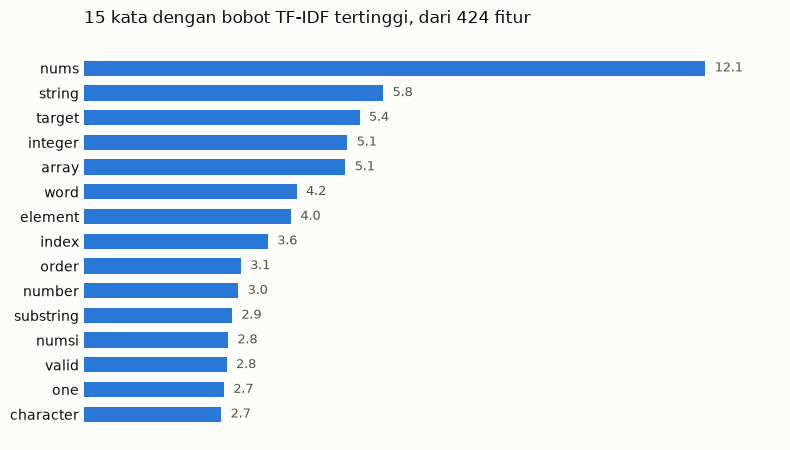

In [13]:
bobot_tfidf = np.asarray(X_tfidf.sum(axis=0)).ravel()
top15 = (
    pd.DataFrame({'kata': fitur_tfidf, 'bobot': bobot_tfidf})
    .sort_values('bobot', ascending=False)
    .head(15)
    .iloc[::-1]                       # dibalik supaya terbesar di atas
)

SURFACE, TEKS_UTAMA, TEKS_SEKUNDER = "#fcfcfb", "#0b0b0b", "#52514e"

fig, ax = plt.subplots(figsize=(8, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

# Satu seri data, jadi satu warna saja: panjang batang sudah membawa besarannya.
ax.barh(top15['kata'], top15['bobot'], height=0.62, color="#2a78d6")

# Label langsung di ujung batang, sehingga sumbu x tidak diperlukan.
for y_pos, bobot in enumerate(top15['bobot']):
    ax.text(bobot + top15['bobot'].max() * 0.015, y_pos, f"{bobot:.1f}",
            va="center", fontsize=9, color=TEKS_SEKUNDER)

ax.set_title(f"15 kata dengan bobot TF-IDF tertinggi, dari {len(fitur_tfidf):,} fitur",
             fontsize=12, color=TEKS_UTAMA, pad=14, loc="left")
ax.set_xlim(0, top15['bobot'].max() * 1.12)
ax.xaxis.set_visible(False)
for sisi in ("top", "right", "bottom", "left"):
    ax.spines[sisi].set_visible(False)
ax.tick_params(colors=TEKS_UTAMA, length=0, labelsize=10)

plt.tight_layout()
plt.show()

## Tahap 7: Menyimpan Hasil Vektorisasi

Empat jenis berkas disimpan ke `Dataset/vectorized/`.

**Matriks fitur** disimpan sebagai `.npz`. Formatnya sparse, artinya cuma sel yang
tidak nol yang ikut ditulis. Karena 94 persen selnya nol, ini menghemat ruang
banyak sekali.

**Label** disimpan sebagai `.npy`.

**Objek vectorizer dan encoder** disimpan sebagai `.pkl`. Ini yang paling penting
dan sering terlewat. Kalau nanti ada soal baru yang mau diprediksi, teksnya harus
diubah memakai kosakata yang sama persis dengan saat training. Melatih vectorizer
baru akan menghasilkan urutan kolom yang berbeda dan modelnya jadi salah baca.

**Daftar fitur** disimpan sebagai XLSX supaya bisa dibuka dan dibaca manusia.

In [14]:
VEKTOR_DIR = DATASET_DIR / "vectorized"
VEKTOR_DIR.mkdir(parents=True, exist_ok=True)

# 1. Matriks fitur (format sparse, hemat ruang)
sp.save_npz(VEKTOR_DIR / "X_bow.npz", X_bow)
sp.save_npz(VEKTOR_DIR / "X_tfidf.npz", X_tfidf)
sp.save_npz(VEKTOR_DIR / "X_tfidf_bigram.npz", X_bigram)

# 2. Label
np.save(VEKTOR_DIR / "y.npy", y)

# 3. Objek vectorizer + encoder, supaya data baru bisa memakai kosakata yang sama
with open(VEKTOR_DIR / "vectorizers.pkl", "wb") as f:
    pickle.dump({
        "bow": bow_vectorizer,
        "tfidf": tfidf_vectorizer,
        "bigram": bigram_vectorizer,
        "label_encoder": encoder,
    }, f)

# 4. Daftar fitur dalam bentuk yang gampang dibaca manusia
pd.DataFrame({
    "kata": fitur_tfidf,
    "bobot_total_tfidf": np.asarray(X_tfidf.sum(axis=0)).ravel().round(4),
    "muncul_di_n_dokumen": np.asarray((X_bow > 0).sum(axis=0)).ravel(),
}).sort_values("bobot_total_tfidf", ascending=False).to_excel(
    VEKTOR_DIR / "daftar_fitur_tfidf.xlsx", index=False
)

print("Tersimpan di", VEKTOR_DIR, "\n")
for berkas in sorted(VEKTOR_DIR.iterdir()):
    print(f"  {berkas.name:<28} {berkas.stat().st_size / 1024:>8.1f} KB")

Tersimpan di /Users/alif/PycharmProjects/Text-Mining/Dataset/vectorized 

  X_bow.npz                         5.0 KB
  X_tfidf.npz                      15.2 KB
  X_tfidf_bigram.npz               19.8 KB
  daftar_fitur_tfidf.xlsx          13.3 KB
  vectorizers.pkl                  36.6 KB
  y.npy                             0.8 KB


### Membuktikan hasil simpanan bisa dipakai lagi

Sel penutup ini memuat ulang berkas yang baru ditulis, persis seperti yang nanti
dilakukan notebook klasifikasi.

Bagian terakhirnya menguji satu kalimat baru yang belum pernah ada di dataset.
Perhatikan bahwa yang dipakai adalah `transform`, bukan `fit_transform`. Bedanya
penting: `transform` memakai kosakata yang sudah ada, sedangkan `fit_transform`
akan membuat kosakata baru dan merusak kecocokan dengan model.

Hasilnya menunjukkan berapa kata dari kalimat itu yang dikenali. Kata yang tidak
ada di kosakata training memang diabaikan, dan itu perilaku yang benar.

In [15]:
X_dimuat = sp.load_npz(VEKTOR_DIR / "X_tfidf.npz")
y_dimuat = np.load(VEKTOR_DIR / "y.npy")

with open(VEKTOR_DIR / "vectorizers.pkl", "rb") as f:
    objek = pickle.load(f)

print(f"X_tfidf dimuat : {X_dimuat.shape}")
print(f"y dimuat       : {y_dimuat.shape}, kelas {list(objek['label_encoder'].classes_)}")
print(f"Cocok dengan X asli: {X_dimuat.shape == X_tfidf.shape}")

# Uji transformasi kalimat baru memakai kosakata yang sudah dilatih
kalimat_baru = ["given an array of integer find the maximum sum of subarray"]
vektor_baru = objek['tfidf'].transform(kalimat_baru)
print(f"\nKalimat baru -> vektor {vektor_baru.shape}, {vektor_baru.nnz} kata dikenali")

X_tfidf dimuat : (90, 424)
y dimuat       : (90,), kelas ['Easy', 'Hard', 'Medium']
Cocok dengan X asli: True

Kalimat baru -> vektor (1, 424), 6 kata dikenali


## Ringkasan

Tiga representasi yang dihasilkan notebook ini:

| Representasi | Jumlah fitur | Berkas |
|---|---|---|
| Bag of Words | 424 | `Dataset/vectorized/X_bow.npz` |
| TF-IDF unigram | 424 | `Dataset/vectorized/X_tfidf.npz` |
| TF-IDF unigram + bigram | 919 | `Dataset/vectorized/X_tfidf_bigram.npz` |

### Alur dua notebook

```
01_Pengambilan_Data.ipynb
    scraping, cleaning, tokenizing, filtering, lemmatization
        |
        v
    Dataset/dataset_leetcode_cleaned.xlsx
        |
        v
02_Vektorisasi.ipynb
    Bag of Words, TF-IDF, N-gram
        |
        v
    Dataset/vectorized/
        |
        v
    tahap berikutnya: klasifikasi
```

### Langkah berikutnya

Untuk tahap klasifikasi, muat berkas hasil vektorisasi lalu bagi datanya. Pakai
`stratify=y` karena sebaran kelasnya tidak seimbang, supaya proporsi Easy, Medium,
dan Hard di data latih dan data uji tetap sama.

```python
import scipy.sparse as sp, numpy as np
from sklearn.model_selection import train_test_split

X = sp.load_npz("Dataset/vectorized/X_tfidf.npz")
y = np.load("Dataset/vectorized/y.npy")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
```